# MovieLens: from data to a hybrid recommender

This notebook backs the decisions in the README: what the data looks like, why the
evaluation is temporal, how the models compare, and what the recommendations look
like for a known user, a new user and a single movie.

In [1]:
import os
from pathlib import Path

os.chdir(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from recsys.data import download, load, to_implicit
from recsys.embeddings import embed_movies
from recsys.evaluation import evaluate
from recsys.models.base import top_k
from recsys.models.classic import ImplicitALS, ItemKNN, Popularity
from recsys.models.content import ContentBased, Hybrid
from recsys.pipeline import prepare

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ratings, movies = load(download())
print(f"{len(ratings):,} ratings · {ratings.userId.nunique()} users · {movies.movieId.nunique():,} movies")

100,836 ratings · 610 users · 9,742 movies


## 1. The data is sparse and long-tailed

Top 10% of movies receive 60% of ratings; matrix density 1.70%


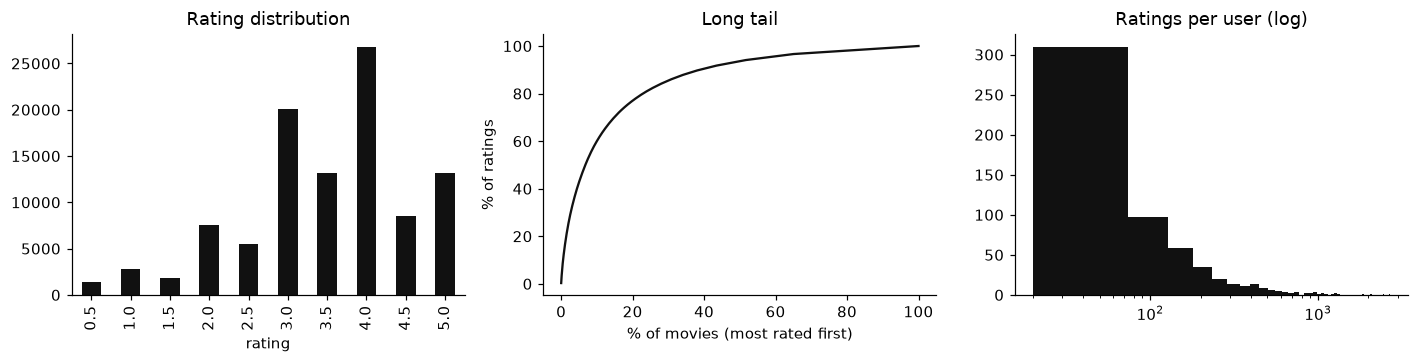

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
ratings["rating"].value_counts().sort_index().plot.bar(ax=axes[0], color="#111")
axes[0].set_title("Rating distribution")

per_movie = ratings.groupby("movieId").size().sort_values(ascending=False).to_numpy()
share = np.cumsum(per_movie) / per_movie.sum()
axes[1].plot(np.arange(1, len(share) + 1) / len(share) * 100, share * 100, color="#111")
axes[1].set_xlabel("% of movies (most rated first)")
axes[1].set_ylabel("% of ratings")
axes[1].set_title("Long tail")

per_user = ratings.groupby("userId").size()
axes[2].hist(per_user, bins=50, color="#111")
axes[2].set_xscale("log")
axes[2].set_title("Ratings per user (log)")
plt.tight_layout()

top10 = share[int(len(share) * 0.1)] * 100
density = len(ratings) / (ratings.userId.nunique() * movies.movieId.nunique()) * 100
print(f"Top 10% of movies receive {top10:.0f}% of ratings; matrix density {density:.2f}%")

Two consequences: a popularity baseline will be hard to beat on accuracy, and a model
that only ever recommends the head of the catalogue will look fine on Recall while being
useless for discovery. That is why coverage and novelty are reported next to accuracy.

## 2. Temporal evaluation

In [3]:
ds = prepare(Path("data/ml-latest-small"))
implicit = to_implicit(ratings)
print(f"Positive interactions (rating >= 3.5): {len(implicit):,} of {len(ratings):,}")
print(f"Train: {ds.train.nnz:,} · Test (each user's latest 20%): {len(ds.test):,}")

Positive interactions (rating >= 3.5): 61,716 of 100,836
Train: 49,619 · Test (each user's latest 20%): 12,097


## 3. Model comparison (hyper-parameters from `recsys evaluate --tune`)

In [4]:
emb = embed_movies(ds.movies, Path("artifacts/item_embeddings.npy"))
models = {
    "popularity": Popularity(),
    "item_knn": ItemKNN(neighbours=200),
    "als": ImplicitALS(factors=32, regularization=0.01, alpha=10.0),
    "content": ContentBased(emb),
    "hybrid": Hybrid(ImplicitALS(factors=32, regularization=0.01, alpha=10.0), ContentBased(emb)),
}
rows = []
for name, model in models.items():
    report = evaluate(model.fit(ds.train), ds.train, ds.test, ds.index)
    rows.append(report.as_row())
results = pd.DataFrame(rows).set_index("model")
results[["recall", "ndcg", "coverage", "novelty", "cold_recall"]].round(3)

,recall,ndcg,coverage,novelty,cold_recall
model,,,,,
popularity,0.070,0.069,0.007,8.340,0.072
item_knn,0.101,0.092,0.022,8.912,0.123
als,0.102,0.087,0.073,9.583,0.143
content,0.012,0.010,0.075,14.026,0.023
hybrid,0.105,0.092,0.076,9.646,0.156


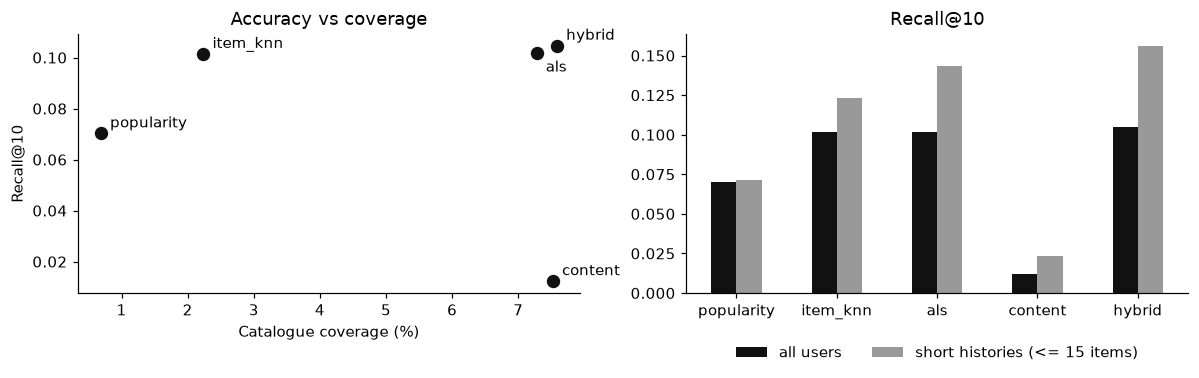

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for name, row in results.iterrows():
    axes[0].scatter(row.coverage * 100, row.recall, s=60, color="#111")
    offset = (6, -12) if name == "als" else (6, 4)
    axes[0].annotate(name, (row.coverage * 100, row.recall), textcoords="offset points", xytext=offset)
axes[0].set_xlabel("Catalogue coverage (%)")
axes[0].set_ylabel("Recall@10")
axes[0].set_title("Accuracy vs coverage")
results[["recall", "cold_recall"]].rename(
    columns={"recall": "all users", "cold_recall": "short histories (<= 15 items)"}
).plot.bar(ax=axes[1], color=["#111", "#999"], rot=0)
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
axes[1].set_xlabel("")
axes[1].set_title("Recall@10")
plt.tight_layout()

**Reading the results.** Item-kNN and ALS are close on accuracy, but ALS recommends from
a catalogue three times larger, with more novel titles. Content embeddings alone are weak
(tastes are not just genres), but in the hybrid they help most where collaborative
filtering is weakest: users with short histories.

## 4. What the recommendations look like

In [6]:
hybrid = models["hybrid"]
title = ds.movies["title"].to_numpy()
user_id = 1
user = ds.index.users[user_id]
history = ds.train[user].indices
print("Recently liked:", "; ".join(title[history[-5:]]))
recs = top_k(hybrid.score(user, ds.train), history, 10)
pd.DataFrame({"recommended": title[recs], "genres": ds.movies["genres"].to_numpy()[recs]})

Recently liked: Big Trouble in Little China (1986); Shaft (2000); X-Men (2000); What About Bob? (1991); Transformers: The Movie (1986)


,recommended,genres
0,Die Hard (1988),Action|Crime|Thriller
1,Glory (1989),Drama|War
2,"Breakfast Club, The (1985)",Comedy|Drama
3,Caddyshack (1980),Comedy
4,2001: A Space Odyssey (1968),Adventure|Drama|Sci-Fi
5,"Hunt for Red October, The (1990)",Action|Adventure|Thriller
6,Shakespeare in Love (1998),Comedy|Drama|Romance
7,Mallrats (1995),Comedy|Romance
8,Animal House (1978),Comedy
9,Blade Runner (1982),Action|Sci-Fi|Thriller


In [7]:
# A brand-new user who liked three animated films: ALS fold-in, no retraining.
liked_titles = ["Toy Story (1995)", "Finding Nemo (2003)", "Shrek (2001)"]
liked = [int(np.where(title == t)[0][0]) for t in liked_titles]
scores = models["als"].fold_in(liked)
pd.Series(title[top_k(scores, np.array(liked, dtype=np.int32), 10)], name="for a new user")

0                                Monsters, Inc. (2001)
1        Lord of the Rings: The Two Towers, The (2002)
2    Lord of the Rings: The Fellowship of the Ring,...
3                                  Forrest Gump (1994)
4    Lord of the Rings: The Return of the King, The...
5                              Incredibles, The (2004)
6           Life Is Beautiful (La Vita è bella) (1997)
7                     Shawshank Redemption, The (1994)
8    Pirates of the Caribbean: The Curse of the Bla...
9                                   Toy Story 2 (1999)
Name: for a new user, dtype: str

In [8]:
matrix = int(np.where(title == "Matrix, The (1999)")[0][0])
knn = models["item_knn"]
similar = top_k(np.asarray(knn.similarity[matrix].todense()).ravel(), np.array([matrix], dtype=np.int32), 8)
pd.Series(title[similar], name="similar to The Matrix")

0                                    Fight Club (1999)
1                           Saving Private Ryan (1998)
2    Lord of the Rings: The Return of the King, The...
3    Lord of the Rings: The Fellowship of the Ring,...
4            Star Wars: Episode IV - A New Hope (1977)
5    Star Wars: Episode V - The Empire Strikes Back...
6                              Sixth Sense, The (1999)
7        Lord of the Rings: The Two Towers, The (2002)
Name: similar to The Matrix, dtype: str